In [13]:
import pandas as pd
df=pd.read_csv("superstore.csv",encoding="latin1")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [14]:
df.shape

(9994, 21)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [16]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df.nunique()

Row ID           9994
Order ID         5009
Order Date       1237
Ship Date        1334
Ship Mode           4
Customer ID       793
Customer Name     793
Segment             3
Country             1
City              531
State              49
Postal Code       631
Region              4
Product ID       1862
Category            3
Sub-Category       17
Product Name     1850
Sales            5825
Quantity           14
Discount           12
Profit           7287
dtype: int64

In [19]:
df.groupby("Category")["Sales"].sum()

Category
Furniture          741999.7953
Office Supplies    719047.0320
Technology         836154.0330
Name: Sales, dtype: float64

In [20]:
df.groupby("Region")["Profit"].sum()

Region
Central     39706.3625
East        91522.7800
South       46749.4303
West       108418.4489
Name: Profit, dtype: float64

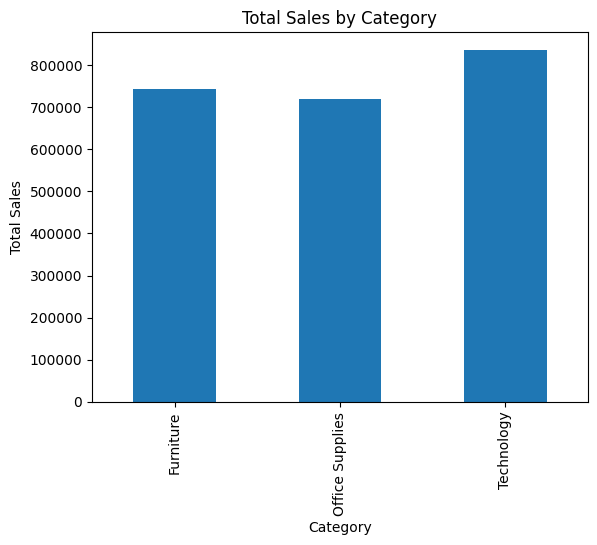

In [22]:
# Import libraries
import matplotlib.pyplot as plt

# Group data by Category and calculate total Sales
category_sales = df.groupby("Category")["Sales"].sum()

# Create bar chart
category_sales.plot(kind="bar")

# Add titles and labels
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")

# Show chart
plt.show()

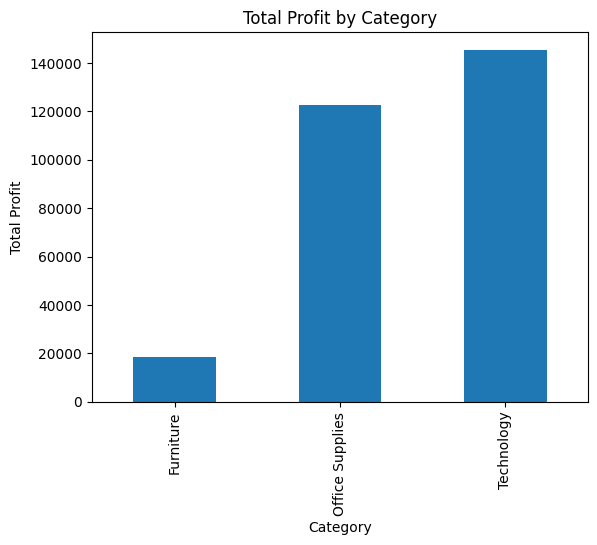

In [23]:
# Profit by Category
category_profit = df.groupby("Category")["Profit"].sum()

# Plot profit chart
category_profit.plot(kind="bar")

plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")

plt.show()


In [24]:
# Find loss making products
loss_products = df[df["Profit"] < 0]

# Show top loss products
loss_products_sorted = loss_products.sort_values(by="Profit")

loss_products_sorted[["Product Name", "Category", "Sales", "Profit"]].head(10)


,Product Name,Category,Sales,Profit
7772,Cubify CubeX 3D Printer Double Head Print,Technology,4499.985,-6599.9780
683,Cubify CubeX 3D Printer Triple Head Print,Technology,7999.980,-3839.9904
9774,GBC DocuBind P400 Electric Binding System,Office Supplies,2177.584,-3701.8928
3011,Lexmark MX611dhe Monochrome Laser Printer,Technology,2549.985,-3399.9800
4991,Ibico EPK-21 Electric Binding System,Office Supplies,1889.990,-2929.4845
3151,Cubify CubeX 3D Printer Double Head Print,Technology,1799.994,-2639.9912
5310,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,1525.188,-2287.7820
9639,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,4297.644,-1862.3124
1199,GBC DocuBind P400 Electric Binding System,Office Supplies,1088.792,-1850.9464
2697,Cisco TelePresence System EX90 Videoconferenci...,Technology,22638.480,-1811.0784


In [ ]:
# Create recommendation column

def recommend_action(profit):
    if profit < -2000:
        return "Stop Selling / Review Pricing"
    elif profit < 0:
        return "Reduce Discount"
    else:
        return "Healthy Product"

df["Recommendation"] = df["Profit"].apply(recommend_action)

# Show decisions for worst products
df[df["Profit"] < 0][
    ["Product Name", "Category", "Sales", "Profit", "Recommendation"]
].sort_values(by="Profit").head(10)


,Product Name,Category,Sales,Profit,Recommendation
7772,Cubify CubeX 3D Printer Double Head Print,Technology,4499.985,-6599.9780,Stop Selling / Review Pricing
683,Cubify CubeX 3D Printer Triple Head Print,Technology,7999.980,-3839.9904,Stop Selling / Review Pricing
9774,GBC DocuBind P400 Electric Binding System,Office Supplies,2177.584,-3701.8928,Stop Selling / Review Pricing
3011,Lexmark MX611dhe Monochrome Laser Printer,Technology,2549.985,-3399.9800,Stop Selling / Review Pricing
4991,Ibico EPK-21 Electric Binding System,Office Supplies,1889.990,-2929.4845,Stop Selling / Review Pricing
3151,Cubify CubeX 3D Printer Double Head Print,Technology,1799.994,-2639.9912,Stop Selling / Review Pricing
5310,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,1525.188,-2287.7820,Stop Selling / Review Pricing
9639,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,4297.644,-1862.3124,Reduce Discount
1199,GBC DocuBind P400 Electric Binding System,Office Supplies,1088.792,-1850.9464,Reduce Discount
2697,Cisco TelePresence System EX90 Videoconferenci...,Technology,22638.480,-1811.0784,Reduce Discount


: 

In [ ]:
import pandas as pd
df=pd.read_csv("superstore.csv",encoding="latin1")
df.head()
df.shape
df.info()
df.describe()
df.duplicated().sum()
df.nunique()
df.groupby("Category")["Sales"].sum()
df.groupby("Region")["Profit"].sum()
# Import libraries
import matplotlib.pyplot as plt

# Group data by Category and calculate total Sales
category_sales = df.groupby("Category")["Sales"].sum()

# Create bar chart
category_sales.plot(kind="bar")

# Add titles and labels
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")

# Show chart
plt.show()

 #Profit by Category
category_profit = df.groupby("Category")["Profit"].sum()

# Plot profit chart
category_profit.plot(kind="bar")

plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")

# Find loss making products
loss_products = df[df["Profit"] < 0]

# Show top loss products
loss_products_sorted = loss_products.sort_values(by="Profit")

loss_products_sorted[["Product Name", "Category", "Sales", "Profit"]].head(10)
# Create recommendation column

def recommend_action(profit):
    if profit < -2000:
        return "Stop Selling / Review Pricing"
    elif profit < 0:
        return "Reduce Discount"
    else:
        return "Healthy Product"

df["Recommendation"] = df["Profit"].apply(recommend_action)

# Show decisions for worst products
df[df["Profit"] < 0][
    ["Product Name", "Category", "Sales", "Profit", "Recommendation"]
].sort_values(by="Profit").head(10)






SyntaxError: invalid syntax (104464378.py, line 3)